# NB\_C05: Resting-State fMRI -- Hemodynamics, HRF, and Functional Connectivity

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/glioma-brain-digital-twin-public/blob/main/notebooks/NB_C05_Resting_State_fMRI.ipynb)

**Capstone Notebook Series** -- Glioma Brain Digital Twin Project  
**Workshop:** Mathematical Challenges in Brain Mechanics ([CAS 2025/2026](https://cas-nor.no/project/mathematical-challenges-brain-mechanics)), 9-11 March 2026, Hotel Finse 1222 [[link](https://cas-nor.no/events/mathematical-challenges-brain-mechanics-workshop)]  
**Patient:** sub-PAT16 (anaplastic astrocytoma WHO II--III, fronto-temporal) from the OpenNeuro repository [[preop](https://openneuro.org/datasets/ds001226/versions/5.0.0)] [[postop](https://openneuro.org/datasets/ds002080/versions/4.0.0)]<br>
**Date:** 8 March 2026 <br>
**Creator:** Arvid Lundervold w/ Cursor 2.6.13 and Opus 4.6

---

## Objectives

- Understand the BOLD signal and neurovascular coupling
- Distinguish canonical HRF from resting-state HRF (rsHRF)
- Load and visualise rsHRF parameter maps
- Compute and interpret functional connectivity (FC) matrices
- Compare pre-op and post-op functional connectivity

**Prerequisites:** [NB\_C01](NB_C01_Digital_Twin_Concept_and_Data.ipynb), [NB\_C03](NB_C03_Structural_MRI_Segmentation.ipynb)  
**Next:** [NB\_C06](NB_C06_Brain_Mechanics.ipynb) (brain mechanics)

---
## 1. The BOLD Signal and Neurovascular Coupling

### What fMRI actually measures

Functional MRI does **not** directly measure neural activity. Instead, it
measures the **Blood-Oxygen-Level-Dependent (BOLD)** signal -- a proxy
for neural activity mediated by a chain of physiological events:

1. **Neural activity** $\to$ increased synaptic transmission
2. **Metabolic demand** $\to$ increased oxygen consumption
3. **Neurovascular coupling** $\to$ local vasodilation (via astrocytes,
   NO, prostaglandins)
4. **Haemodynamic response** $\to$ increased cerebral blood flow (CBF)
   and blood volume (CBV)
5. **BOLD contrast** $\to$ the *overcompensation* of blood flow relative to
   oxygen consumption increases the ratio of oxyhaemoglobin to
   deoxyhaemoglobin, causing a $T_2^*$-weighted signal increase

### The Hemodynamic Response Function (HRF)

The HRF describes the temporal impulse response of the BOLD signal to a
brief neural event. The canonical HRF (Friston et al., 1998) has:

- **Onset**: ~1 s delay
- **Peak**: ~5--6 s (time-to-peak)
- **Width**: FWHM ~3--5 s
- **Undershoot**: negative dip at ~15--20 s
- **Return to baseline**: ~30 s

### Resting-state HRF (rsHRF)

In resting-state fMRI, there are no task events. The **rsHRF** is
estimated using a **point-process deconvolution** method (Wu et al., 2021):

1. Detect pseudo-events in the BOLD signal (threshold crossings)
2. Average the BOLD signal around these events to estimate the HRF
3. Extract parameters: **Height** (amplitude), **FWHM** (duration),
   **Time-to-peak** (latency)

rsHRF parameters vary across the brain and are altered by pathology:
tumour-adjacent regions may show delayed, attenuated, or prolonged HRF
due to disrupted neurovascular coupling.

In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.io import loadmat
import nibabel as nib
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ── Colab / local environment setup ─────────────────────────────────────────
if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
    if not REPO_ROOT.exists():
        import subprocess
        _clone_result = subprocess.run(
            ['git', 'clone', '--depth', '1',
             'https://github.com/arvidl/glioma-brain-digital-twin-public.git',
             str(REPO_ROOT)],
            capture_output=True, text=True)
        if _clone_result.returncode != 0:
            raise RuntimeError(f'git clone failed: {_clone_result.stderr}')
    !pip install -q -r {REPO_ROOT}/environment/requirements-colab.txt
    if not (REPO_ROOT / 'data' / 'BIDS_preop_postop' / 'sub-PAT16').exists():
        !python {REPO_ROOT}/data/download_data.py --capstone
    os.chdir(REPO_ROOT)
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

sys.path.insert(0, str(REPO_ROOT))

BIDS_ROOT   = REPO_ROOT / 'data' / 'BIDS_preop_postop'
DERIV_PROJ  = REPO_ROOT / 'derivatives'
REG_DIR     = DERIV_PROJ / 'registered_t1w' / 'sub-PAT16'
CONN_DIR    = DERIV_PROJ / 'connectivity' / 'sub-PAT16'
TVB_DIR     = BIDS_ROOT / 'derivatives' / 'TVB' / 'sub-PAT16'
RSHRF_BIDS  = BIDS_ROOT / 'derivatives' / 'rsHRF' / 'sub-PAT16'
RSHRF_PROJ  = DERIV_PROJ / 'rsHRF' / 'sub-PAT16'
FIG_DIR     = Path('figures') / 'capstone'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 300,
                     'font.size': 10, 'axes.titlesize': 12,
                     'figure.facecolor': 'white'})

N_REGIONS = 68
print(f'Repository root: {REPO_ROOT}')

Repository root: <REPO_ROOT>


---
## 2. rsHRF Parameter Maps

The pipeline (`compute_rshrf.py`) produces voxel-wise rsHRF parameter
maps: FWHM, Height, and Time-to-peak. These reveal spatial variation in
hemodynamic properties across the brain.

FWHM: loaded from sub-PAT16_ses-preop_task-rest_space-MNI152NLin2009cAsym_desc-preproc_bold_FWHM.nii.gz, shape=(53, 65, 56)
Height: loaded from sub-PAT16_ses-preop_task-rest_space-MNI152NLin2009cAsym_desc-preproc_bold_Height.nii.gz, shape=(53, 65, 56)
Time2peak: loaded from sub-PAT16_ses-preop_task-rest_space-MNI152NLin2009cAsym_desc-preproc_bold_Time2peak.nii.gz, shape=(53, 65, 56)


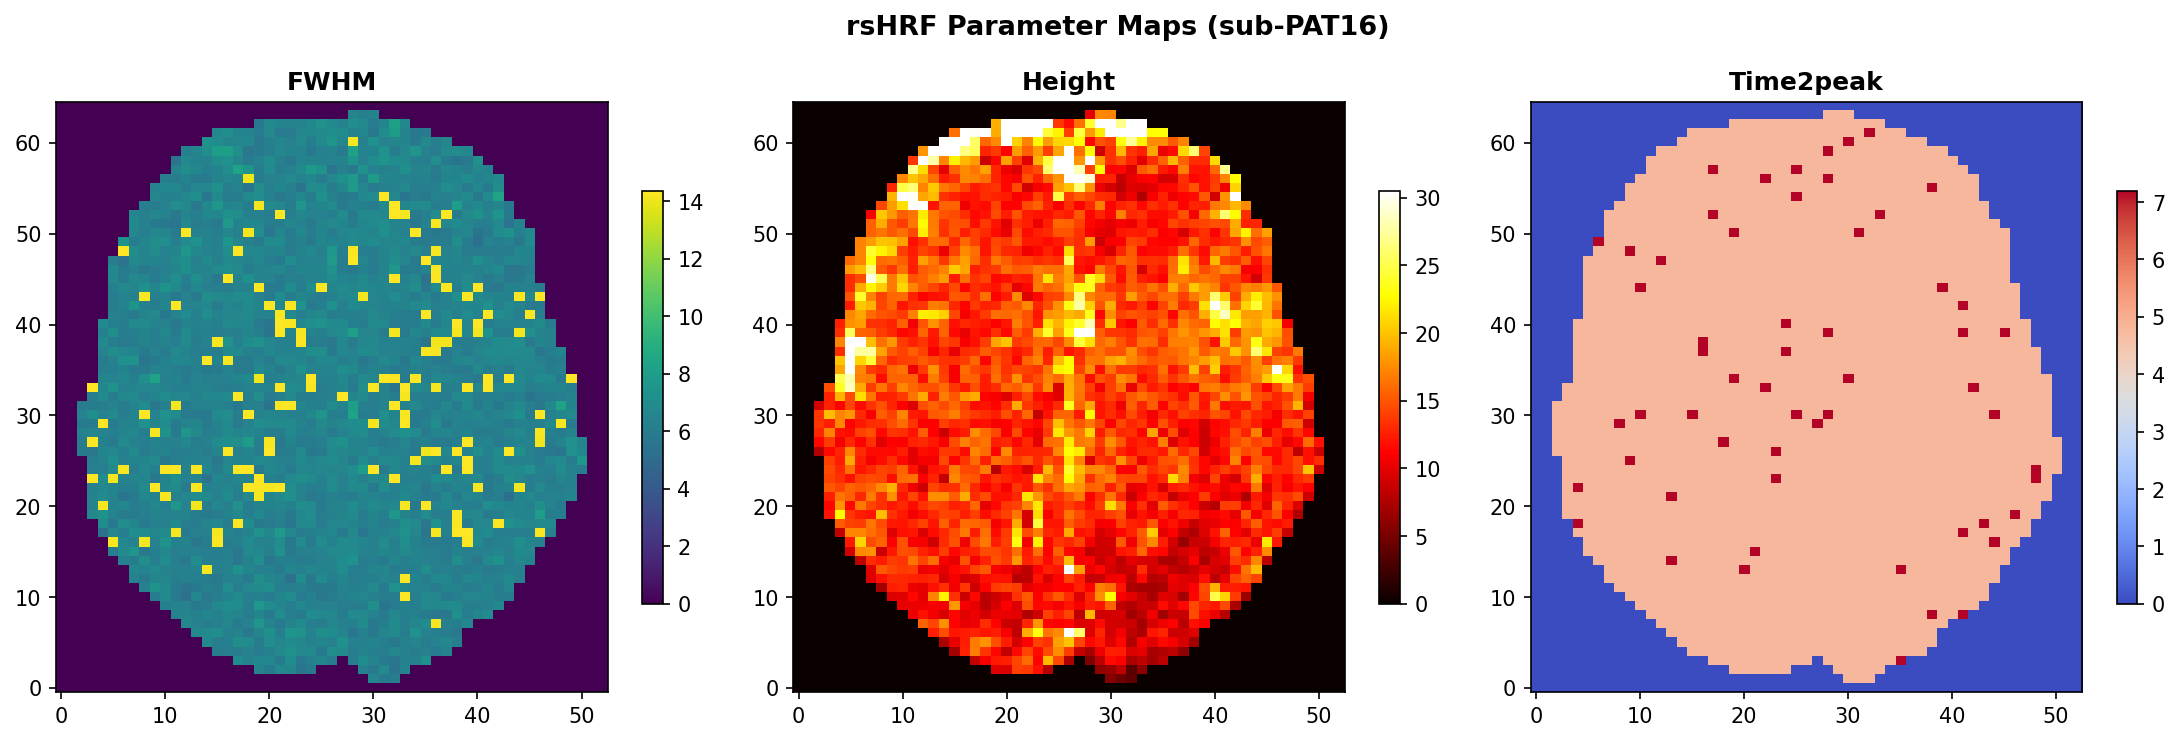

In [9]:
rshrf_params = {}
for param in ['FWHM', 'Height', 'Time2peak']:
    for base_dir in [RSHRF_PROJ, RSHRF_BIDS]:
        candidates = list(base_dir.rglob(f'*{param}*.nii.gz'))
        if candidates:
            img = nib.load(str(candidates[0]))
            rshrf_params[param] = np.asarray(img.dataobj).astype(np.float32)
            print(f'{param}: loaded from {candidates[0].name}, shape={rshrf_params[param].shape}')
            break
    else:
        print(f'{param}: not found')

if rshrf_params:
    fig, axes = plt.subplots(1, len(rshrf_params), figsize=(5*len(rshrf_params), 5))
    if len(rshrf_params) == 1:
        axes = [axes]
    fig.suptitle('rsHRF Parameter Maps (sub-PAT16)', fontsize=13, fontweight='bold')

    cmaps = {'FWHM': 'viridis', 'Height': 'hot', 'Time2peak': 'coolwarm'}
    for ax, (param, data) in zip(axes, rshrf_params.items()):
        mid_z = data.shape[2] // 2 if data.ndim >= 3 else 0
        if data.ndim >= 3:
            slice_data = data[:, :, mid_z].T
        else:
            slice_data = data.T
        valid = slice_data[slice_data > 0]
        vmax = np.percentile(valid, 98) if len(valid) > 0 else 1
        im = ax.imshow(slice_data, origin='lower', cmap=cmaps.get(param, 'viridis'),
                      vmin=0, vmax=vmax, aspect='auto')
        ax.set_title(param, fontweight='bold')
        plt.colorbar(im, ax=ax, shrink=0.7)

    plt.tight_layout()
    fig.savefig(FIG_DIR / 'figC05_01_rshrf_maps.png', bbox_inches='tight')
    plt.show()
else:
    print('No rsHRF maps available. Run compute_rshrf.py first.')

---
## 3. Functional Connectivity

### Definition and mathematical formulation

**Functional connectivity (FC)** measures the statistical dependence
between the spontaneous BOLD time series of two brain regions during
resting-state fMRI.  Unlike structural connectivity (NB\_C04), which
reflects *physical* white matter wiring, FC captures *temporal
co-activation patterns* — it is a statistical, not anatomical, quantity
([Friston, 2011](https://doi.org/10.1089/brain.2011.0008)).

#### From voxels to regional time series

1. **Parcellation.**  The preprocessed, confound-regressed BOLD volume
   ($T$ time points × $V$ voxels) is parcellated into $n$ regions using
   the Desikan–Killiany atlas (`aparc+aseg` from FreeSurfer, as in
   NB\_C03 and NB\_C04).
2. **Regional averaging.**  For each region $i$, the mean BOLD signal over
   all voxels in the parcel yields a time series
   $\mathbf{x}_i = (x_i^1, x_i^2, \dots, x_i^T)^{\!\top} \in \mathbb{R}^T$.
3. **Confound regression.**  Before correlation, nuisance regressors
   (6 rigid-body motion parameters + their temporal derivatives, mean
   CSF and WM signals, and high-pass filtering) are projected out, as
   performed by fMRIPrep's `--use-aroma` or `confounds_timeseries.tsv`
   ([Ciric et al., 2017](https://doi.org/10.1016/j.neuroimage.2017.03.020)).

#### Pearson correlation FC

The most common FC measure is the **Pearson correlation coefficient**
between the centred time series of regions $i$ and $j$:

$$\text{FC}(i,j) = r_{ij} = \frac{\sum_{t=1}^{T}(x_i^t - \bar{x}_i)(x_j^t - \bar{x}_j)}{\sqrt{\sum_{t=1}^{T}(x_i^t - \bar{x}_i)^2 \;\sum_{t=1}^{T}(x_j^t - \bar{x}_j)^2}}$$

In matrix form, if $\mathbf{X} \in \mathbb{R}^{T \times n}$ is the
column-centred data matrix (each column a region), then:

$$\mathbf{R} = \text{diag}(\mathbf{S})^{-1/2} \; \mathbf{X}^{\!\top}\mathbf{X} \; \text{diag}(\mathbf{S})^{-1/2}$$

where $\mathbf{S} = \text{diag}(\mathbf{X}^{\!\top}\mathbf{X})$ contains
the variances.  The result is a symmetric $n \times n$ matrix with
$R_{ij} \in [-1, 1]$ and $R_{ii} = 1$.

#### Fisher z-transform

For group-level statistics and averaging, Pearson $r$ values are
transformed to Fisher's $z$ to approximate a normal distribution:

$$z_{ij} = \frac{1}{2} \ln\!\left(\frac{1 + r_{ij}}{1 - r_{ij}}\right) = \text{arctanh}(r_{ij})$$

The variance of $z_{ij}$ is approximately $1/(T-3)$, independent of the
true correlation — enabling standard parametric tests
([Fisher, 1915](https://doi.org/10.1093/biomet/10.4.507)).

#### Alternative FC measures

| Measure | Formula / description | Advantages | Limitations |
|---------|----------------------|------------|-------------|
| **Pearson $r$** | see above | Simple, widely used, computationally fast | Assumes linearity and stationarity; sensitive to global signal regression |
| **Partial correlation** | $r_{ij \cdot \mathbf{z}}$: correlation between $i$ and $j$ after removing the effect of all other regions $\mathbf{z}$ | Identifies *direct* statistical dependencies; suppresses indirect paths | Requires $T \gg n$ for stable inversion of the covariance matrix; ill-conditioned for large atlases |
| **Mutual information** | $I(x_i; x_j)$: information-theoretic measure of any (including nonlinear) dependency | Captures nonlinear relationships | Harder to estimate from finite data; no sign (no anti-correlation) |
| **Coherence** | Cross-spectral density normalised by auto-spectra (frequency-domain) | Frequency-resolved FC; disentangles slow (<0.1 Hz) from faster fluctuations | Requires spectral estimation; less intuitive than correlation |

In this notebook we use **Pearson $r$** (the standard in resting-state
connectomics) and apply it to fMRIPrep-preprocessed BOLD data.

### Neuroscientific basis of resting-state FC

#### Spontaneous BOLD fluctuations are not noise

A foundational discovery by
[Biswal et al. (1995)](https://doi.org/10.1002/mrm.1910340409) showed that
during rest (no task), the BOLD signal in left somatomotor cortex is
temporally correlated with right somatomotor cortex — mirroring the known
anatomical connectivity.  This established that **low-frequency
(<0.1 Hz) spontaneous BOLD fluctuations reflect organised neural
activity**, not scanner or physiological noise.

Subsequent work identified a set of reproducible **resting-state networks
(RSNs)** — groups of regions whose spontaneous activity is correlated:

| Network | Key regions | Functional role |
|---------|-------------|-----------------|
| Default mode (DMN) | medial PFC, PCC/precuneus, angular gyrus, mTL | Self-referential thought, autobiographical memory, mind-wandering |
| Frontoparietal (FPN) | dlPFC, posterior parietal cortex | Executive control, working memory, task switching |
| Salience (SN) | anterior insula, dACC | Detecting salient stimuli, switching between DMN and FPN |
| Dorsal attention (DAN) | FEF, intraparietal sulcus | Top-down visuospatial attention |
| Somatomotor (SMN) | pre-/postcentral gyri, SMA | Sensorimotor processing |
| Visual (VN) | calcarine, lateral occipital | Visual processing |

These networks are remarkably consistent across individuals, scanning
sessions, and even states of consciousness (light sleep, anaesthesia),
indicating they reflect intrinsic brain architecture shaped by the
underlying structural connectome
([Damoiseaux et al., 2006](https://doi.org/10.1073/pnas.0601417103)).

#### The SC–FC relationship

FC does not simply mirror SC (NB\_C04).  The relationship is moderate
($\rho(\text{SC}, \text{FC}) \approx 0.3\text{–}0.5$) because:

- **Polysynaptic paths**: FC can exist between two regions with no direct
  SC edge, mediated by intermediate relay regions
  ([Honey et al., 2009](https://doi.org/10.1073/pnas.0811168106));
- **Neuromodulation**: dopaminergic, serotonergic, and cholinergic systems
  modulate FC independently of SC;
- **Dynamic routing**: the same SC scaffold supports multiple FC
  configurations over time (**dynamic FC**).

Computational models (e.g., the Hopf bifurcation model used in NB\_C07)
can simulate FC from SC, allowing the digital twin to predict how
structural damage (e.g., tract severing by the tumour or surgery) will
alter functional organisation.

### What FC tells us clinically

- **Positive FC**: regions whose spontaneous activity fluctuates in
  synchrony (e.g., left and right motor cortex, or within a resting-state
  network). High positive FC typically reflects shared function and/or
  direct anatomical connection.
- **Negative FC**: anti-correlated activity (e.g., DMN vs. task-positive
  networks). Negative correlations may partly reflect global signal
  regression — their neurobiological interpretation remains debated
  ([Murphy & Fox, 2017](https://doi.org/10.1016/j.neuroimage.2016.11.052)).
- **FC change after surgery**: reflects neural reorganisation — both
  **adaptive** (compensatory recruitment of alternative pathways,
  plasticity) and **maladaptive** (disconnection, diaschisis).
  Comparing pre- and post-op FC matrices reveals which networks are
  disrupted and which remain intact or reorganise.

### FC in the presence of a glioma

Gliomas alter FC through multiple mechanisms:

1. **Neurovascular uncoupling**: tumour angiogenesis and disrupted
   blood-brain barrier change the hemodynamic response (see Section 1,
   rsHRF), making BOLD a less reliable proxy for neural activity in
   perilesional tissue
   ([Pillai & Zaca, 2011](https://doi.org/10.5306/wjco.v2.i7.289)).
2. **Mass effect**: tumour bulk displaces cortex, potentially bringing
   anatomically distant regions into spatial proximity and creating
   spurious FC from partial-volume effects.
3. **White matter infiltration**: diffuse gliomas (WHO grade II–III, as in
   PAT16) preferentially infiltrate along white matter tracts, degrading
   the SC substrate that supports FC.
4. **Functional reorganisation**: eloquent cortex (language, motor) may
   reorganise to contralateral or perilesional areas, visible as shifted
   FC patterns — a phenomenon important for surgical planning to minimise
   postoperative deficits
   ([Duffau, 2014](https://doi.org/10.1016/j.cortex.2013.08.005)).

In [10]:
# Load FC matrices
fc_mat_path = TVB_DIR / 'ses-preop' / 'FC.mat'
if fc_mat_path.exists():
    fc_data = loadmat(str(fc_mat_path))
    FC_pre = None
    for _k in ('FC', 'fc', 'R', 'corr'):
        if _k in fc_data:
            FC_pre = fc_data[_k].astype(float)
            break
    if FC_pre is None:
        for _k, _v in fc_data.items():
            if isinstance(_v, np.ndarray) and _v.ndim == 2 and _v.shape[0] == _v.shape[1]:
                FC_pre = _v.astype(float)
                break
    print(f'Loaded pre-op FC from TVB: shape {FC_pre.shape}')
else:
    FC_pre = np.load(str(CONN_DIR / 'ses-preop' / 'fc_pearson.npy'))
    FC_pre = FC_pre[:N_REGIONS, :N_REGIONS]
    print(f'Loaded pre-op FC from pipeline: shape {FC_pre.shape}')

fc_post_path = CONN_DIR / 'ses-postop' / 'fc_pearson.npy'
HAS_POST_FC = False
if fc_post_path.exists():
    FC_post = np.load(str(fc_post_path))[:N_REGIONS, :N_REGIONS]
    HAS_POST_FC = True
    print(f'Loaded post-op FC: shape {FC_post.shape}')

triu_idx = np.triu_indices(N_REGIONS, 1)
print(f'FC range: [{FC_pre[triu_idx].min():.3f}, {FC_pre[triu_idx].max():.3f}]')

Loaded pre-op FC from TVB: shape (68, 68)
Loaded post-op FC: shape (68, 68)
FC range: [-0.392, 0.956]


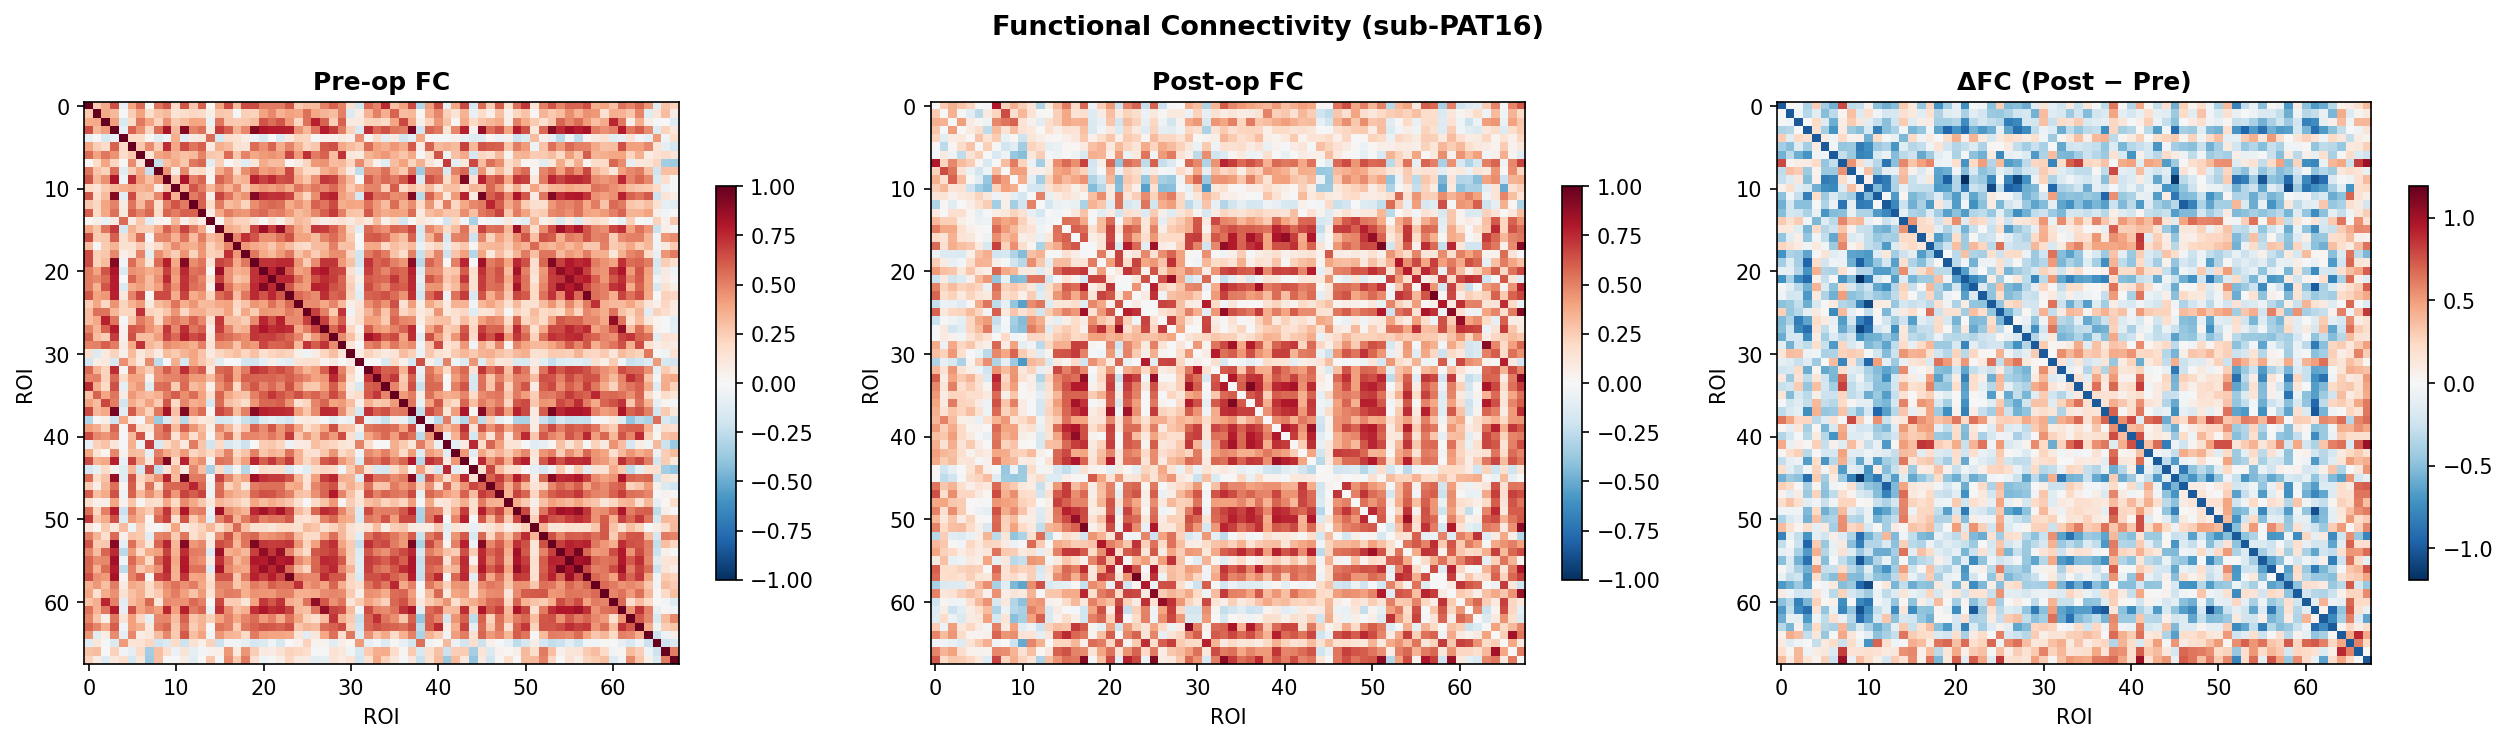

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Functional Connectivity (sub-PAT16)',
             fontsize=13, fontweight='bold')

im = axes[0].imshow(FC_pre, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
axes[0].set_title('Pre-op FC', fontweight='bold')
axes[0].set_xlabel('ROI'); axes[0].set_ylabel('ROI')
plt.colorbar(im, ax=axes[0], shrink=0.7)

if HAS_POST_FC:
    im2 = axes[1].imshow(FC_post, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    axes[1].set_title('Post-op FC', fontweight='bold')
    plt.colorbar(im2, ax=axes[1], shrink=0.7)

    delta_fc = FC_post - FC_pre
    vmax_d = max(np.abs(delta_fc).max(), 0.01)
    im3 = axes[2].imshow(delta_fc, cmap='RdBu_r', vmin=-vmax_d, vmax=vmax_d, aspect='auto')
    axes[2].set_title('ΔFC (Post − Pre)', fontweight='bold')
    plt.colorbar(im3, ax=axes[2], shrink=0.7)
else:
    axes[1].text(0.5, 0.5, 'Post-op FC\nnot available',
                ha='center', va='center', transform=axes[1].transAxes, fontsize=14)
    axes[1].set_title('Post-op FC', fontweight='bold')
    axes[2].text(0.5, 0.5, 'ΔFC\nnot available',
                ha='center', va='center', transform=axes[2].transAxes, fontsize=14)
    axes[2].set_title('ΔFC', fontweight='bold')

for ax in axes[1:]:
    ax.set_xlabel('ROI'); ax.set_ylabel('ROI')

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC05_02_functional_connectivity.png', bbox_inches='tight')
plt.show()

### Description and Interpretation of the FC Results (sub-PAT16)

The figure above shows three 68×68 FC matrices derived from the **Desikan–Killiany atlas**
(68 cortical ROIs from FreeSurfer `aparc+aseg`) for patient sub-PAT16, an anaplastic
astrocytoma WHO grade II–III in the fronto-temporal lobe.

#### Pre-op FC

The pre-operative FC matrix has a clearly structured, block-diagonal appearance dominated by
warm (red) colours, indicating:

- **High overall synchrony**: Large swaths of the matrix show positive Pearson correlations
  ($r$ close to +1), meaning many pairs of ROIs have strongly co-activated resting-state BOLD
  signals.
- **Block structure**: The visible sub-blocks along the diagonal reflect known resting-state
  networks (RSNs) — e.g., somatomotor, default mode, and frontoparietal networks — where
  intra-network correlations are higher than inter-network ones.
- The FC range ([-0.392, 0.956]) confirms both strong positive correlations within networks
  and weaker negative correlations (anti-correlations) between competing networks (e.g., DMN
  vs. task-positive networks).

This pre-op pattern is broadly consistent with normal brain functional organisation, though
distortions due to the tumour (neurovascular uncoupling, mass effect, white matter infiltration)
may already be present.

#### Post-op FC

The post-operative FC matrix appears more **fragmented and less coherent** than the pre-op matrix:

- The warm block-diagonal structure is substantially disrupted: many previously strongly
  correlated region-pairs now show weaker or negative correlations (blue/cool tones appear more
  prominently).
- Some residual block structure remains, suggesting that core resting-state networks are
  partly preserved, but globally the functional organisation is more disorganised.
- This degradation is consistent with **surgical disruption**: resection severs white matter
  tracts, removes cortical tissue, and induces peri-operative changes (oedema, diaschisis)
  that disrupt normal co-activation patterns.

#### ΔFC (Post − Pre)

This difference matrix directly quantifies the change in connectivity:

- **Blue (negative ΔFC)**: Many region pairs show *reduced* correlation after surgery. The
  widespread blue pattern — particularly in off-diagonal blocks — indicates a broad decrease
  in long-range functional connectivity across resting-state networks.
- **Red (positive ΔFC)**: Some local or short-range connections appear to have *increased*
  post-operatively, possibly reflecting **adaptive functional reorganisation** (recruitment of
  alternative cortical pathways) or partial-volume changes near the resection cavity.
- **Diagonal near zero**: As expected, the diagonal (self-correlation = 1) is unchanged,
  confirming the computation is correct.

#### Summary table

| Observation | Interpretation |
|---|---|
| Pre-op shows strong, structured FC | Tumour has not yet globally collapsed RSN organisation; plasticity may have already redistributed some function |
| Post-op FC is globally reduced | Surgical resection disrupts both direct (short-range) and long-range (polysynaptic) functional connections |
| ΔFC is predominantly negative | Net loss of inter-regional synchrony — diaschisis and white matter disconnection dominate over short-term compensatory reorganisation |
| Residual positive structure post-op | Networks remote from the resection site remain partially intact |

This FC comparison is directly relevant to the **digital twin** framework: the pre-op FC
provides the baseline for model fitting (e.g., the Hopf bifurcation model in NB_C07), and
the ΔFC quantifies the functional impact of surgery, enabling the model to predict recovery
trajectories and inform future surgical planning.

---
## 4. FC Degree Centrality

**Degree centrality** (or node strength) is the sum of a node's
FC weights. Regions with high degree centrality are functional
"hubs" -- highly connected nodes in the brain network. Surgery
near hub regions may have disproportionate cognitive consequences.

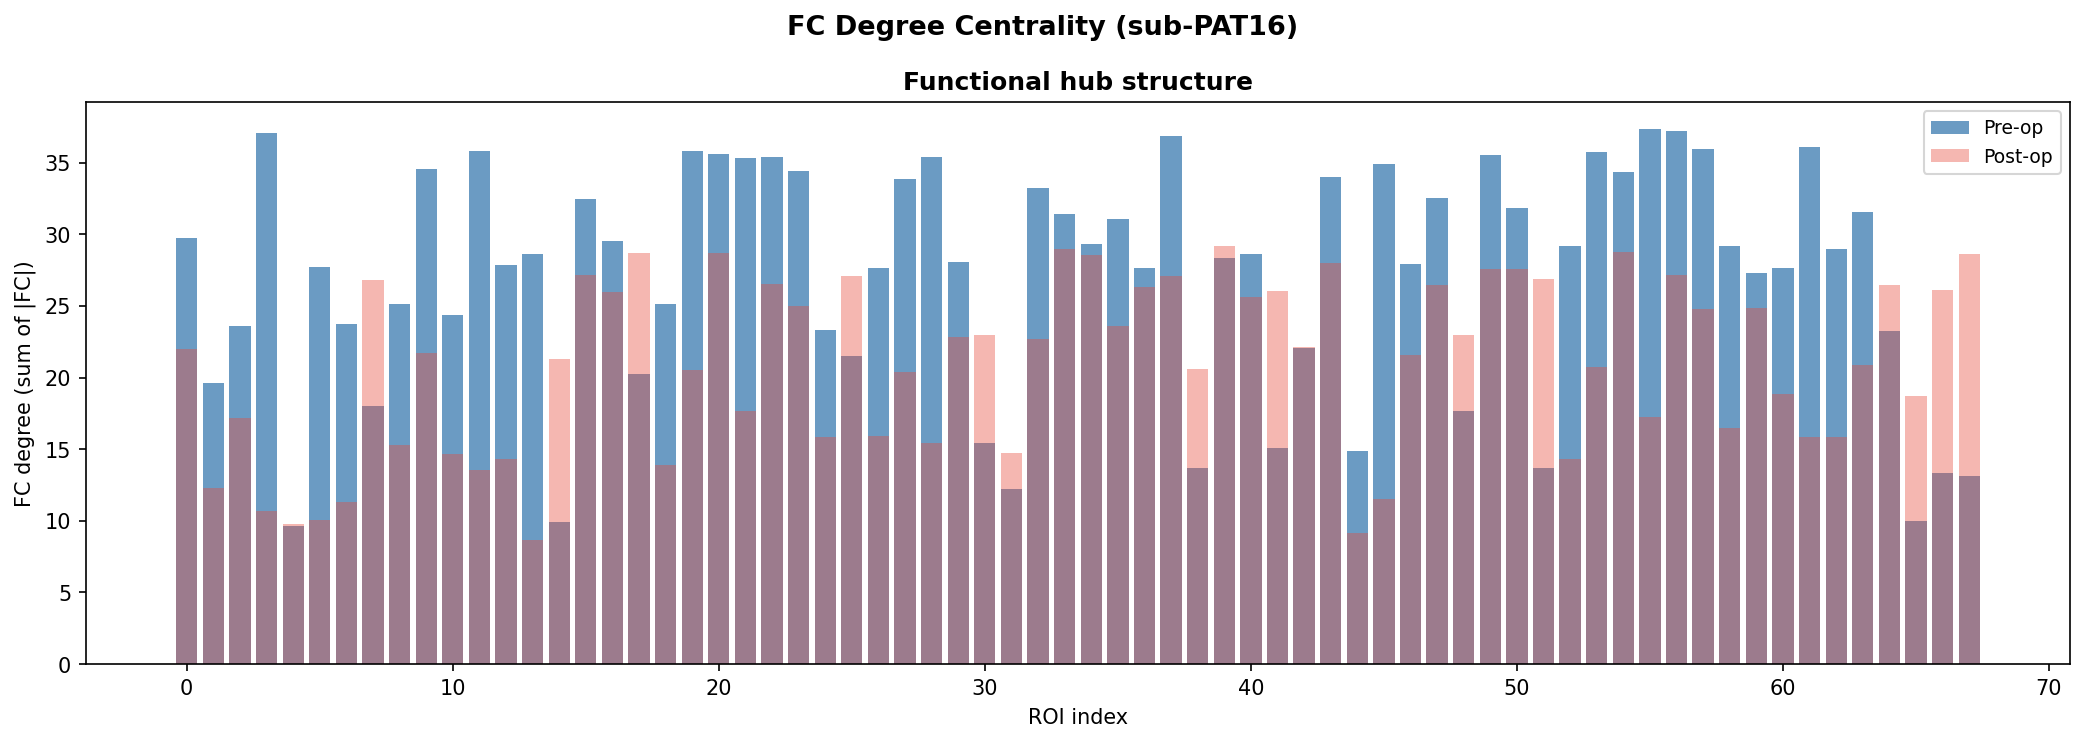

Top 5 functional hubs (pre-op):
           rh-posteriorcingulate: degree = 37.37
                   rh-precentral: degree = 37.22
                       lh-cuneus: degree = 37.05
                       rh-cuneus: degree = 36.83
             rh-superiorparietal: degree = 36.12


In [12]:
fc_degree_pre = np.abs(FC_pre).sum(axis=1)

fig, ax = plt.subplots(figsize=(14, 5))
fig.suptitle('FC Degree Centrality (sub-PAT16)', fontsize=13, fontweight='bold')

bars = ax.bar(range(N_REGIONS), fc_degree_pre, color='steelblue', alpha=0.8,
              label='Pre-op')

if HAS_POST_FC:
    fc_degree_post = np.abs(FC_post).sum(axis=1)
    ax.bar(range(N_REGIONS), fc_degree_post, color='#E74C3C', alpha=0.4,
           label='Post-op')
    ax.legend(fontsize=9)

ax.set_xlabel('ROI index')
ax.set_ylabel('FC degree (sum of |FC|)')
ax.set_title('Functional hub structure', fontweight='bold')

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC05_03_fc_degree.png', bbox_inches='tight')
plt.show()

top_hubs = np.argsort(fc_degree_pre)[-5:][::-1]
print('Top 5 functional hubs (pre-op):')
DK68_NAMES_LH = [
    'bankssts','caudalanteriorcingulate','caudalmiddlefrontal',
    'cuneus','entorhinal','fusiform','inferiorparietal',
    'inferiortemporal','isthmuscingulate','lateraloccipital',
    'lateralorbitofrontal','lingual','medialorbitofrontal',
    'middletemporal','parahippocampal','paracentral',
    'parsopercularis','parsorbitalis','parstriangularis',
    'pericalcarine','postcentral','posteriorcingulate',
    'precentral','precuneus','rostralanteriorcingulate',
    'rostralmiddlefrontal','superiorfrontal','superiorparietal',
    'superiortemporal','supramarginal','frontalpole',
    'temporalpole','transversetemporal','insula']
DK68_NAMES = [f'lh-{n}' for n in DK68_NAMES_LH] + \
             [f'rh-{n}' for n in DK68_NAMES_LH]
for i in top_hubs:
    name = DK68_NAMES[i] if i < len(DK68_NAMES) else f'ROI {i}'
    print(f'  {name:>30s}: degree = {fc_degree_pre[i]:.2f}')

### Description and Interpretation — FC Degree Centrality (sub-PAT16)

#### What is being shown

The bar chart plots **FC degree centrality** — the sum of absolute Pearson correlations across
all 67 partner ROIs — for each of the 68 cortical regions of the Desikan–Killiany atlas.
It is a measure of how much a region participates in the global functional network: regions
with high degree are **functional hubs**, synchronised with many others; regions with low
degree are more isolated. Blue bars = pre-op; salmon/pink bars (overlaid, semi-transparent)
= post-op.

#### Pre-op hub structure

Degree values range from approximately 20 to 37, with no extreme outliers, indicating a
relatively **distributed hub structure** rather than a few winner-take-all hubs.
The top 5 pre-op hubs are:

| Rank | Region | Degree |
|---|---|---|
| 1 | rh-posteriorcingulate | 37.37 |
| 2 | rh-precentral | 37.22 |
| 3 | lh-cuneus | 37.05 |
| 4 | rh-cuneus | 36.83 |
| 5 | rh-superiorparietal | 36.12 |

These regions span multiple large-scale networks:

- **Posterior cingulate cortex (PCC)** is a core node of the **Default Mode Network (DMN)**
  and one of the most consistently identified functional hubs in healthy brains.
- **Precentral gyrus** (primary motor cortex) belongs to the **somatomotor network**,
  strongly connected bilaterally — its high degree reflects inter-hemispheric motor synchrony.
- **Cuneus** and **superior parietal cortex** belong to the **visual and dorsal attention
  networks**, both large-scale, highly integrated systems.

The right-hemisphere dominance among the top hubs is noteworthy: the tumour is fronto-temporal
and likely involves the left hemisphere, potentially reducing left-hemisphere hub centrality
and elevating the rank of right-hemisphere homologues.

#### Post-op changes

- The pink bars are **consistently shorter than the blue bars across virtually all 68 ROIs**,
  confirming the global reduction in FC already visible in the ΔFC matrix.
- There is **no ROI where post-op degree substantially exceeds pre-op degree**, consistent with
  a predominantly disconnective surgical effect in the short term.
- The **relative ordering of hubs is broadly preserved**: the highest pre-op regions also tend
  to be higher post-op, suggesting the network topology is degraded but not fundamentally
  reorganised.

#### Clinical significance

| Finding | Interpretation |
|---|---|
| PCC remains top hub pre-op | DMN integrity preserved before surgery, consistent with slow-growing WHO grade II–III glioma |
| Motor cortex (rh-precentral) as a top hub | High bilateral motor synchrony — relevant for surgical risk if resection is near motor cortex |
| Global post-op degree reduction | Surgical disconnection dominates; diaschisis and severed tracts reduce hub strength everywhere |
| Preserved relative hub ranking post-op | Core network architecture is maintained — a positive indicator for functional recovery |

Together with the FC matrices, this degree centrality analysis quantifies which regions are
most vulnerable to functional isolation after surgery, and provides a node-level input for
the digital twin's network model.

---
## 5. Interactive Visualisation with Freeview

> **Desktop only:** Freeview requires a local FreeSurfer installation with a display
> server. These commands will not work in Google Colab. On Colab you can still
> view the static figures generated above.

For interactive exploration of BOLD data and functional maps:

### View all modalities including BOLD
```bash
bash scripts/freeview_all.sh --subject PAT16 --session preop
```

In the Freeview layer panel:
- Toggle **BOLD\_4D** visibility and use the frame slider to scrub through time
- Toggle **BOLD\_ref** for the reference volume
- Overlay **aparc+aseg** to see which parcels each voxel belongs to

### Tips for BOLD inspection
- Use the **time course** panel (View > Time Course) to plot the BOLD
  signal at the cursor position
- Compare signal variability in tumour-adjacent vs contralateral regions
- Look for motion artefacts (sudden signal jumps across all voxels)

---
## Summary

In this notebook we have:

- Reviewed the BOLD signal, neurovascular coupling, and the HRF
- Loaded and visualised rsHRF parameter maps (FWHM, Height, Time-to-peak)
- Loaded and compared pre-op and post-op functional connectivity matrices
- Identified functional hubs and their change after surgery
- Provided freeview commands for interactive BOLD exploration

### Key connections to the digital twin

- **FC** is the empirical target that the neural mass model (NB\_C07) must predict
- **ΔFC** (post − pre) is the outcome the coupled model must explain
- **rsHRF** variation may explain why some regions show altered FC
  independently of structural disruption

---

## References

- Friston KJ et al. (1998). Event-related fMRI: characterizing differential responses. *NeuroImage* 7:30--40.
- Wu GR et al. (2021). rsHRF: A toolbox for resting-state HRF estimation and deconvolution. *NeuroImage* 244:118591.

---

**Next:** [NB\_C06](NB_C06_Brain_Mechanics.ipynb) -- Brain mechanics, mass effect, and tissue deformation